BASE_DIR: C:\Users\user\Documents\GitHub\Group-4-Assignment-2-Two-


,k,wcss,pct_reduction_from_prev_k,mean_silhouette
0,1,96.000000,NaN,NaN
1,2,44.987525,53.137994,0.558507
2,3,5.468465,87.844487,0.816812
3,4,3.487623,36.222992,0.738770
4,5,2.186294,37.312773,0.629311
5,6,1.322473,39.510753,0.619576


Saved: C:\Users\user\Documents\GitHub\Group-4-Assignment-2-Two-\outputs\part4b_kmeans_diagnostics.csv
Saved: C:\Users\user\Documents\GitHub\Group-4-Assignment-2-Two-\outputs\part4b_wcss_and_mean_silhouette.png


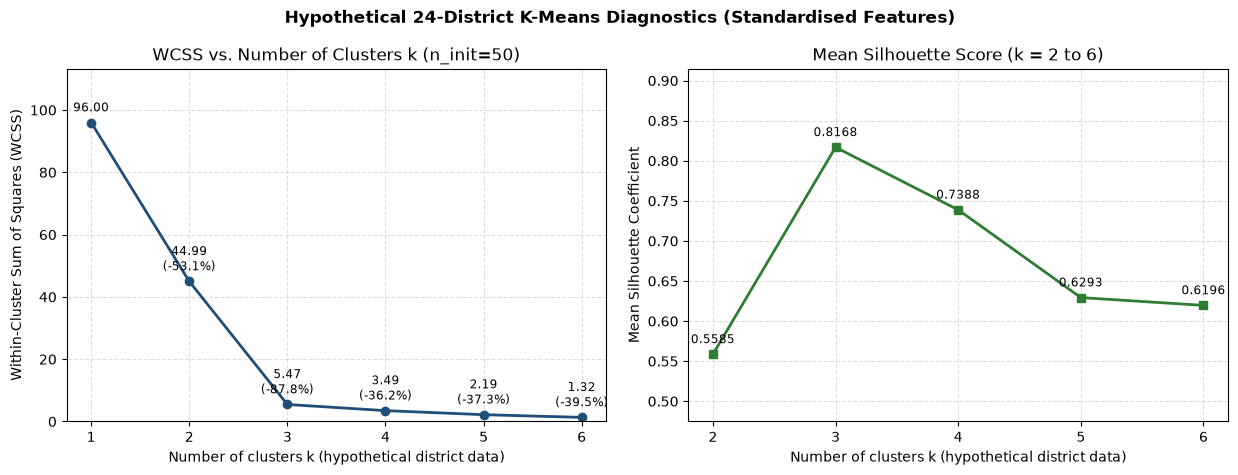

Saved: C:\Users\user\Documents\GitHub\Group-4-Assignment-2-Two-\outputs\part4b_silhouette_profiles_k2_k3.png


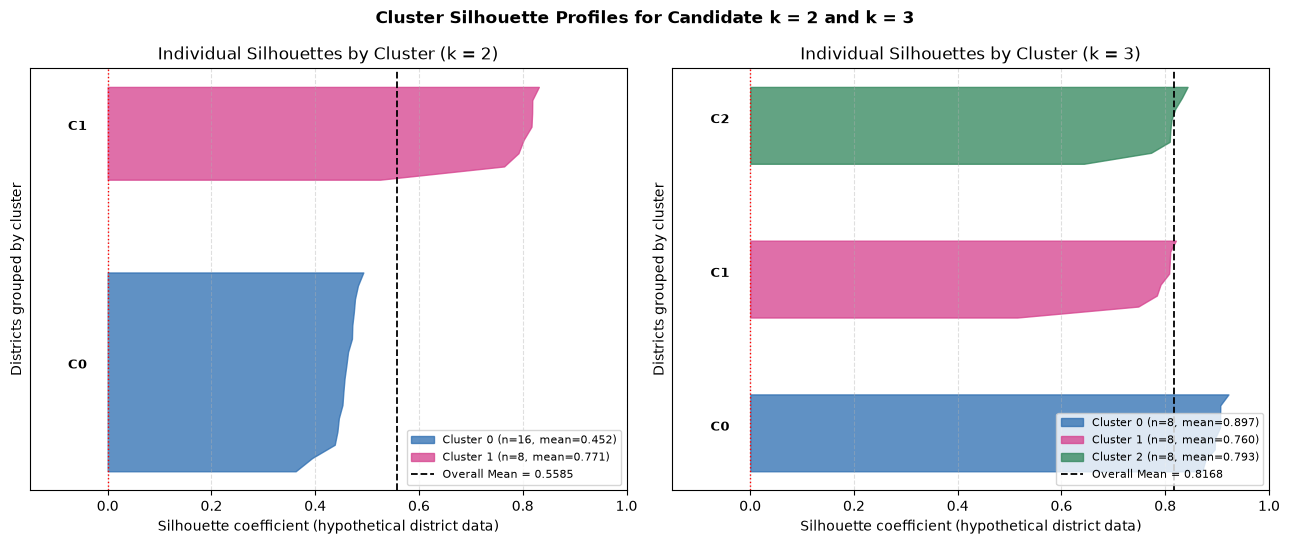

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

%matplotlib inline

# ---------- Paths ----------
def find_base_dir():
    env = os.environ.get("PROJECT_DIR")
    if env and (Path(env) / "data" / "raw").exists():
        return Path(env)
    start = Path.cwd().resolve()
    for p in [start, *start.parents]:
        if (p / "data" / "raw").exists():
            return p
    try:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk()
        root.withdraw()
        root.attributes("-topmost", True)
        chosen = filedialog.askdirectory(title="Select the project folder (the one containing data/raw)")
        root.destroy()
    except Exception:
        chosen = input("Paste the project folder path: ").strip().strip('"')
    if chosen and (Path(chosen) / "data" / "raw").exists():
        return Path(chosen)
    raise FileNotFoundError("data/raw not found in the selected folder.")

BASE_DIR = find_base_dir()
RAW_DIR = BASE_DIR / "data" / "raw"
OUT_DIR = BASE_DIR / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("BASE_DIR:", BASE_DIR)

def safe_save(save_fn, filename):
    try:
        save_fn(OUT_DIR / filename)
        print("Saved:", OUT_DIR / filename)
    except OSError as e:
        fallback = Path.home() / "part4b_outputs"
        fallback.mkdir(exist_ok=True)
        save_fn(fallback / filename)
        print("Could not write to", OUT_DIR, "-", e)
        print("Saved to", fallback / filename, "instead.")

# ---------- Data ----------
districts = pd.read_csv(RAW_DIR / "districts.csv")
age_sex = pd.read_csv(RAW_DIR / "age_sex.csv")

# 1. Build 4a features across all 24 districts (hypothetical dataset)
pop25_tot = age_sex.groupby("district_id")["population_2025"].sum()
u15_tot = age_sex[age_sex["age_start"] < 15].groupby("district_id")["population_2025"].sum()
o65_tot = age_sex[age_sex["age_start"] >= 65].groupby("district_id")["population_2025"].sum()

df_4a = districts[["district_id", "district_name", "region", "population_2026",
                   "arrivals_2025", "departures_2025", "piped_water_pct"]].copy()
df_4a["pop_2025"] = df_4a["district_id"].map(pop25_tot)
df_4a["share_u15_pct"] = (df_4a["district_id"].map(u15_tot) / df_4a["pop_2025"]) * 100.0
df_4a["share_65p_pct"] = (df_4a["district_id"].map(o65_tot) / df_4a["pop_2025"]) * 100.0
exposure_2025 = 0.5 * (df_4a["pop_2025"] + df_4a["population_2026"])
df_4a["nmr_2025_per_1000"] = ((df_4a["arrivals_2025"] - df_4a["departures_2025"]) / exposure_2025) * 1000.0
df_4a["piped_water_imputed"] = df_4a["piped_water_pct"].fillna(df_4a["piped_water_pct"].median())

feat_cols = ["share_u15_pct", "share_65p_pct", "nmr_2025_per_1000", "piped_water_imputed"]
X_scaled = StandardScaler().fit_transform(df_4a[feat_cols])

# 2. Fit k-means for k = 1..6 with n_init >= 20 (using n_init=50)
k_values = list(range(1, 7))
wcss_list = []
sil_mean_list = []
labels_dict = {}
sil_samples_dict = {}

for k in k_values:
    km = KMeans(n_clusters=k, n_init=50, random_state=42)
    lbl = km.fit_predict(X_scaled)
    labels_dict[k] = lbl
    wcss_list.append(km.inertia_)
    if k >= 2:
        sil_mean_list.append(silhouette_score(X_scaled, lbl))
        sil_samples_dict[k] = silhouette_samples(X_scaled, lbl)

diag_rows = []
for i, k in enumerate(k_values):
    pct_red = np.nan if i == 0 else ((wcss_list[i - 1] - wcss_list[i]) / wcss_list[i - 1]) * 100.0
    mean_sil = np.nan if i == 0 else sil_mean_list[i - 1]
    diag_rows.append({
        "k": k,
        "wcss": wcss_list[i],
        "pct_reduction_from_prev_k": pct_red,
        "mean_silhouette": mean_sil,
    })

diag_df = pd.DataFrame(diag_rows)
display(diag_df)
safe_save(lambda p: diag_df.to_csv(p, index=False), "part4b_kmeans_diagnostics.csv")

# 3. Plot WCSS vs k and Mean Silhouette (k=2..6)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))

ax1.plot(k_values, wcss_list, marker="o", linewidth=2, color="#1f4e78")
for i, k in enumerate(k_values):
    txt = f"{wcss_list[i]:.2f}" if i == 0 else f"{wcss_list[i]:.2f}\n(-{diag_df.loc[i, 'pct_reduction_from_prev_k']:.1f}%)"
    ax1.annotate(txt, (k, wcss_list[i]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8.5)
ax1.set_title("WCSS vs. Number of Clusters k (n_init=50)")
ax1.set_xlabel("Number of clusters k (hypothetical district data)")
ax1.set_ylabel("Within-Cluster Sum of Squares (WCSS)")
ax1.set_xticks(k_values)
ax1.set_ylim(0, max(wcss_list) * 1.18)
ax1.grid(True, linestyle="--", alpha=0.4)

k2_6 = list(range(2, 7))
ax2.plot(k2_6, sil_mean_list, marker="s", linewidth=2, color="#2e7d32")
for k, s_val in zip(k2_6, sil_mean_list):
    ax2.annotate(f"{s_val:.4f}", (k, s_val), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8.5)
ax2.set_title("Mean Silhouette Score (k = 2 to 6)")
ax2.set_xlabel("Number of clusters k (hypothetical district data)")
ax2.set_ylabel("Mean Silhouette Coefficient")
ax2.set_xticks(k2_6)
ax2.set_ylim(min(sil_mean_list) * 0.85, max(sil_mean_list) * 1.12)
ax2.grid(True, linestyle="--", alpha=0.4)

fig.suptitle("Hypothetical 24-District K-Means Diagnostics (Standardised Features)",
             fontsize=12.5, fontweight="bold")
plt.tight_layout()
safe_save(lambda p: fig.savefig(p, dpi=150), "part4b_wcss_and_mean_silhouette.png")
plt.show()

# 4. Plot individual silhouettes by cluster for two plausible candidates: k = 2 and k = 3
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
colors = ["#2b6cb0", "#d53f8c", "#2f855a"]

for ax, k_cand in zip(axes, [2, 3]):
    lbl = labels_dict[k_cand]
    s_vals = sil_samples_dict[k_cand]
    avg_s = silhouette_score(X_scaled, lbl)
    y_lower = 10
    for c in range(k_cand):
        c_vals = np.sort(s_vals[lbl == c])
        size_c = len(c_vals)
        y_upper = y_lower + size_c
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, c_vals,
                         facecolor=colors[c % len(colors)], edgecolor=colors[c % len(colors)], alpha=0.75,
                         label=f"Cluster {c} (n={size_c}, mean={c_vals.mean():.3f})")
        ax.text(-0.04, y_lower + 0.5 * size_c, f"C{c}", va="center", ha="right", fontsize=9, fontweight="bold")
        y_lower = y_upper + 6
    ax.axvline(avg_s, color="black", linestyle="--", linewidth=1.3, label=f"Overall Mean = {avg_s:.4f}")
    ax.axvline(0.0, color="red", linestyle=":", linewidth=1.0)
    ax.set_title(f"Individual Silhouettes by Cluster (k = {k_cand})")
    ax.set_xlabel("Silhouette coefficient (hypothetical district data)")
    ax.set_ylabel("Districts grouped by cluster")
    ax.set_yticks([])
    ax.set_xlim(-0.15, 1.0)
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.legend(loc="lower right", fontsize=8)

fig.suptitle("Cluster Silhouette Profiles for Candidate k = 2 and k = 3", fontsize=12.5, fontweight="bold")
plt.tight_layout()
safe_save(lambda p: fig.savefig(p, dpi=150), "part4b_silhouette_profiles_k2_k3.png")
plt.show()